# Upgrades: honest threshold selection, feature ablation, confidence intervals

Run this **after** the main notebook (it needs `featured_transactions.csv` in the same folder).

| # | Upgrade | What it fixes |
|---|---|---|
| 1 | Train / validation / test split; thresholds chosen on **validation**, test scored **once** | In the main notebook the thresholds (0.982 and 0.09) were chosen on the test set, so the reported operating-point numbers are optimistic |
| 2 | Feature ablation with 5-fold CV (never touches the test set) | Shows whether the engineered features actually help over V1-V28 |
| 3 | Bootstrap 95% confidence intervals on the test results | With only 98 fraud cases, single numbers hide a lot of uncertainty |
| 4 | Drop `rapid_repeat` | It equals 1 for every row, so it carries no information |

The test set is the **same 20% split** as the main notebook (`random_state=42`, stratified), so results are directly comparable.

In [3]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, confusion_matrix)
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

QUICK_TEST = False        # True = tiny, fast smoke test (do not use for real results)
RANDOM_STATE = 42
COST_FN, COST_FP = 150, 15   # ASSUMED costs, same as the main notebook

# Best parameters found by GridSearchCV in the main notebook
XGB_PARAMS = dict(max_depth=8, learning_rate=0.1, n_estimators=200,
                  subsample=0.8, colsample_bytree=0.8, eval_metric="aucpr",
                  random_state=RANDOM_STATE, n_jobs=-1, verbosity=0)
if QUICK_TEST:
    XGB_PARAMS.update(n_estimators=30, max_depth=4)
N_BOOT = 200 if QUICK_TEST else 1000
print("QUICK_TEST =", QUICK_TEST)

QUICK_TEST = False


## 0. Load data and define feature groups

In [4]:
df = pd.read_csv("featured_transactions.csv")

V        = [f"V{i}" for i in range(1, 29)]
AMOUNT   = ["log_amount", "amt_zscore", "amt_bucket"]
TIME     = ["hour_of_day", "is_night", "time_sin", "time_cos"]
VELOCITY = ["txn_velocity_1h", "txn_velocity_10m"]
RAPID    = ["rapid_repeat"]

missing = [c for c in V + AMOUNT + TIME + VELOCITY + RAPID + ["Class"] if c not in df.columns]
assert not missing, f"Missing columns: {missing}"
print(df.shape, "| fraud:", int(df["Class"].sum()))

(284807, 41) | fraud: 492


## Upgrade 4: drop `rapid_repeat`

Evidence first: if this prints a single value, the feature is constant and useless.

In [5]:
print("rapid_repeat unique values:", sorted(df["rapid_repeat"].unique().tolist()))
print("txn_velocity_10m minimum   :", df["txn_velocity_10m"].min(), "(rapid_repeat = velocity >= 3)")

FEATURES = V + AMOUNT + TIME + VELOCITY      # 37 features, rapid_repeat removed
print("Final feature count:", len(FEATURES))

rapid_repeat unique values: [1]
txn_velocity_10m minimum   : 111 (rapid_repeat = velocity >= 3)
Final feature count: 37


## Upgrade 1: train / validation / test split

- **Test (20%)**: identical to the main notebook's test set. Touched exactly once, in the section below.
- **Train (60%)** fits the model. **Validation (20%)** is used only to choose thresholds.

In [6]:
X, y = df[FEATURES], df["Class"]

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)          # same as main notebook
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, random_state=RANDOM_STATE, stratify=y_trainval)

for name, yy in [("train", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{name:11s}: {len(yy):>7,} rows | fraud {int(yy.sum()):>3} ({yy.mean()*100:.3f}%)")

train      : 170,883 rows | fraud 295 (0.173%)
validation :  56,962 rows | fraud  99 (0.174%)
test       :  56,962 rows | fraud  98 (0.172%)


In [7]:
def make_model(y_fit, **override):
    spw = (y_fit == 0).sum() / (y_fit == 1).sum()          # scale_pos_weight from the training labels
    return XGBClassifier(scale_pos_weight=spw, **{**XGB_PARAMS, **override})

t0 = time.time()
model = make_model(y_train)
model.fit(X_train, y_train)
p_val = model.predict_proba(X_val)[:, 1]
print(f"fit in {time.time()-t0:.0f}s | validation AUC-PR {average_precision_score(y_val, p_val):.4f} "
      f"| AUC-ROC {roc_auc_score(y_val, p_val):.4f}")

fit in 26s | validation AUC-PR 0.8152 | AUC-ROC 0.9775


### Choose thresholds on the validation set only

In [8]:
def confusion(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return int(tn), int(fp), int(fn), int(tp)

def prf(tp, fp, fn):
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec  = tp / (tp + fn) if (tp + fn) else 0.0
    f1   = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return prec, rec, f1

def total_cost(fn, fp):
    return fn * COST_FN + fp * COST_FP

grid = np.round(np.arange(0.01, 1.00, 0.01), 2)
rows = []
for t in grid:
    tn, fp, fn, tp = confusion(y_val, p_val, t)
    prec, rec, f1 = prf(tp, fp, fn)
    rows.append(dict(threshold=t, tp=tp, fp=fp, fn=fn, precision=prec, recall=rec, f1=f1,
                     cost=total_cost(fn, fp)))
sweep = pd.DataFrame(rows)

def pick(col, mode):
    """Best threshold for a column; ties -> median of the tied thresholds (more stable)."""
    target = sweep[col].min() if mode == "min" else sweep[col].max()
    return float(np.median(sweep.loc[sweep[col] == target, "threshold"]))

THR_COST = pick("cost", "min")
THR_F1   = pick("f1", "max")
print(f"Cost-optimal threshold (validation): {THR_COST:.3f}")
print(f"F1-optimal threshold   (validation): {THR_F1:.3f}")
sweep.loc[sweep["threshold"].isin([0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 0.98])].round(4)

Cost-optimal threshold (validation): 0.770
F1-optimal threshold   (validation): 0.980


,threshold,tp,fp,fn,precision,recall,f1,cost
4,0.05,78,30,21,0.7222,0.7879,0.7536,3600
9,0.10,77,20,22,0.7938,0.7778,0.7857,3600
19,0.20,77,14,22,0.8462,0.7778,0.8105,3510
29,0.30,77,12,22,0.8652,0.7778,0.8191,3480
49,0.50,77,11,22,0.8750,0.7778,0.8235,3465
69,0.70,77,7,22,0.9167,0.7778,0.8415,3405
89,0.90,74,6,25,0.9250,0.7475,0.8268,3840
97,0.98,74,2,25,0.9737,0.7475,0.8457,3780


### Score the test set ONCE

Run this cell once. Do not go back and adjust thresholds or parameters after looking at it, or the test set stops being honest.

In [9]:
p_test = model.predict_proba(X_test)[:, 1]
auc_pr_test  = average_precision_score(y_test, p_test)
auc_roc_test = roc_auc_score(y_test, p_test)

def test_row(label, t):
    tn, fp, fn, tp = confusion(y_test, p_test, t)
    prec, rec, f1 = prf(tp, fp, fn)
    return dict(operating_point=label, threshold=round(t, 3), TP=tp, FP=fp, FN=fn,
                precision=round(prec, 4), recall=round(rec, 4), f1=round(f1, 4),
                cost=total_cost(fn, fp))

test_table = pd.DataFrame([
    test_row("cost-optimal (chosen on validation)", THR_COST),
    test_row("F1-optimal (chosen on validation)",   THR_F1),
    test_row("default 0.5",                          0.5),
])
print(f"TEST  AUC-PR {auc_pr_test:.4f} | AUC-ROC {auc_roc_test:.4f}  ({int(y_test.sum())} fraud cases)\n")
print(test_table.to_string(index=False))

print("\nFor comparison - main notebook (threshold 0.09 chosen ON the test set):")
print("  precision 0.8131 | recall 0.8878 | F1 0.8488 | cost $1,950 | AUC-PR 0.8804 | AUC-ROC 0.9766")

TEST  AUC-PR 0.8640 | AUC-ROC 0.9785  (98 fraud cases)

                    operating_point  threshold  TP  FP  FN  precision  recall     f1  cost
cost-optimal (chosen on validation)       0.77  78   7  20     0.9176  0.7959 0.8525  3105
  F1-optimal (chosen on validation)       0.98  75   4  23     0.9494  0.7653 0.8475  3510
                        default 0.5       0.50  81  12  17     0.8710  0.8265 0.8482  2730

For comparison - main notebook (threshold 0.09 chosen ON the test set):
  precision 0.8131 | recall 0.8878 | F1 0.8488 | cost $1,950 | AUC-PR 0.8804 | AUC-ROC 0.9766


## Upgrade 3: bootstrap 95% confidence intervals (test set)

Stratified bootstrap: fraud and legitimate rows are resampled separately, so every resample keeps the original fraud count.

In [10]:
rng = np.random.default_rng(RANDOM_STATE)
yt  = y_test.values
pos = np.where(yt == 1)[0]
neg = np.where(yt == 0)[0]
THRESHOLDS = {"cost-optimal": THR_COST, "F1-optimal": THR_F1}

boot_auc = []
boot_thr = {k: [] for k in THRESHOLDS}
t0 = time.time()
for _ in range(N_BOOT):
    idx = np.concatenate([rng.choice(pos, len(pos)), rng.choice(neg, len(neg))])
    yb, pb = yt[idx], p_test[idx]
    boot_auc.append((average_precision_score(yb, pb), roc_auc_score(yb, pb)))
    for name, t in THRESHOLDS.items():
        pred = pb >= t
        tp = int((pred & (yb == 1)).sum()); fp = int((pred & (yb == 0)).sum())
        fn = int((~pred & (yb == 1)).sum())
        prec, rec, f1 = prf(tp, fp, fn)
        boot_thr[name].append((prec, rec, f1, total_cost(fn, fp)))
print(f"{N_BOOT} bootstrap resamples in {time.time()-t0:.0f}s")

def ci(a):
    a = np.asarray(a); return np.percentile(a, 2.5), np.percentile(a, 97.5)

ci_rows = []
auc_arr = np.asarray(boot_auc)
for j, name in enumerate(["AUC-PR", "AUC-ROC"]):
    lo, hi = ci(auc_arr[:, j])
    ci_rows.append(dict(metric=name, operating_point="threshold-free",
                        estimate=round([auc_pr_test, auc_roc_test][j], 4),
                        ci_low=round(lo, 4), ci_high=round(hi, 4)))
for name, t in THRESHOLDS.items():
    arr = np.asarray(boot_thr[name])
    tn, fp, fn, tp = confusion(y_test, p_test, t)
    prec, rec, f1 = prf(tp, fp, fn)
    for j, (m, est) in enumerate([("precision", prec), ("recall", rec), ("F1", f1),
                                  ("cost ($)", total_cost(fn, fp))]):
        lo, hi = ci(arr[:, j])
        ci_rows.append(dict(metric=m, operating_point=f"{name} ({t:.2f})",
                            estimate=round(est, 4), ci_low=round(lo, 4), ci_high=round(hi, 4)))
ci_table = pd.DataFrame(ci_rows)
ci_table

1000 bootstrap resamples in 108s


,metric,operating_point,estimate,ci_low,ci_high
0,AUC-PR,threshold-free,0.8640,0.7963,0.9212
1,AUC-ROC,threshold-free,0.9785,0.9585,0.9938
2,precision,cost-optimal (0.77),0.9176,0.8621,0.9744
3,recall,cost-optimal (0.77),0.7959,0.7143,0.8673
4,F1,cost-optimal (0.77),0.8525,0.7956,0.9011
5,cost ($),cost-optimal (0.77),3105.0000,2025.0000,4380.3750
6,precision,F1-optimal (0.98),0.9494,0.8974,0.9875
7,recall,F1-optimal (0.98),0.7653,0.6735,0.8469
8,F1,F1-optimal (0.98),0.8475,0.7852,0.8951
9,cost ($),F1-optimal (0.98),3510.0000,2384.2500,4860.3750


## Upgrade 2: feature ablation (5-fold stratified CV on the training portion)

Does adding the engineered features improve on V1-V28 alone? This uses only train + validation rows (**never the test set**) and reports the spread across folds, so you can see whether any difference is bigger than the noise.

In [11]:
FEATURE_SETS = {
    "V1-V28 only":                          V,
    "V + amount features":                  V + AMOUNT,
    "V + time features":                    V + TIME,
    "V + velocity features":                V + VELOCITY,
    "V + amount + time":                    V + AMOUNT + TIME,
    "V + all engineered (final, 37)":       V + AMOUNT + TIME + VELOCITY,
    "V + all engineered + rapid_repeat (original 38)": V + AMOUNT + TIME + VELOCITY + RAPID,
}
D  = df.loc[X_trainval.index]            # train + validation rows only
yD = y_trainval
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(D, yD))

fold_ap, fold_roc = {}, {}
t0 = time.time()
for name, cols in FEATURE_SETS.items():
    aps, rocs = [], []
    for tr, te in folds:
        m = make_model(yD.iloc[tr])
        m.fit(D.iloc[tr][cols], yD.iloc[tr])
        p = m.predict_proba(D.iloc[te][cols])[:, 1]
        aps.append(average_precision_score(yD.iloc[te], p))
        rocs.append(roc_auc_score(yD.iloc[te], p))
    fold_ap[name], fold_roc[name] = np.array(aps), np.array(rocs)
    print(f"{name:52s} AUC-PR {np.mean(aps):.4f} +/- {np.std(aps):.4f}   ({time.time()-t0:.0f}s elapsed)")

V1-V28 only                                          AUC-PR 0.8515 +/- 0.0248   (92s elapsed)
V + amount features                                  AUC-PR 0.8541 +/- 0.0276   (155s elapsed)
V + time features                                    AUC-PR 0.8486 +/- 0.0305   (209s elapsed)
V + velocity features                                AUC-PR 0.8481 +/- 0.0282   (263s elapsed)
V + amount + time                                    AUC-PR 0.8491 +/- 0.0299   (319s elapsed)
V + all engineered (final, 37)                       AUC-PR 0.8441 +/- 0.0323   (379s elapsed)
V + all engineered + rapid_repeat (original 38)      AUC-PR 0.8464 +/- 0.0310   (439s elapsed)


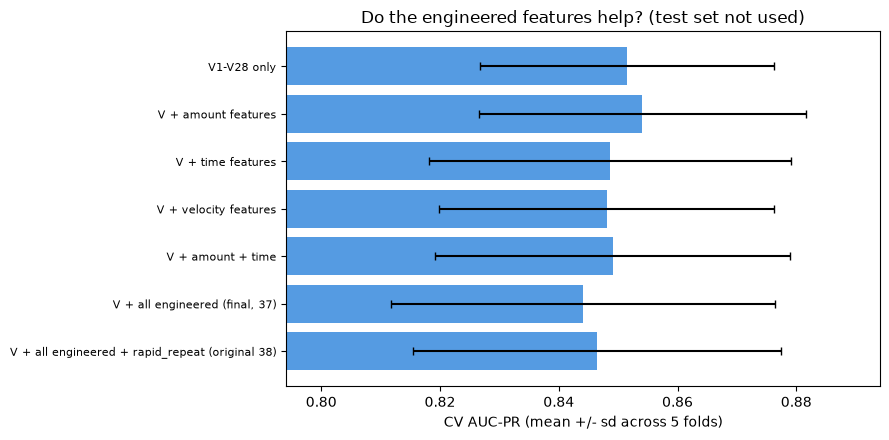

,feature set,n features,CV AUC-PR (mean),CV AUC-PR (sd),CV AUC-ROC (mean),AUC-PR change vs V-only,folds better than V-only
0,V1-V28 only,28,0.8515,0.0248,0.9811,0.0000,-
1,V + amount features,31,0.8541,0.0276,0.9812,0.0026,4/5
2,V + time features,32,0.8486,0.0305,0.9846,-0.0029,2/5
3,V + velocity features,30,0.8481,0.0282,0.9837,-0.0034,2/5
4,V + amount + time,35,0.8491,0.0299,0.9820,-0.0024,3/5
5,"V + all engineered (final, 37)",37,0.8441,0.0323,0.9834,-0.0073,2/5
6,V + all engineered + rapid_repeat (original 38),38,0.8464,0.0310,0.9817,-0.0051,3/5


In [12]:
base = fold_ap["V1-V28 only"]
abl_rows = []
for name in FEATURE_SETS:
    d = fold_ap[name] - base
    abl_rows.append({
        "feature set": name,
        "n features": len(FEATURE_SETS[name]),
        "CV AUC-PR (mean)": round(fold_ap[name].mean(), 4),
        "CV AUC-PR (sd)":   round(fold_ap[name].std(), 4),
        "CV AUC-ROC (mean)": round(fold_roc[name].mean(), 4),
        "AUC-PR change vs V-only": round(d.mean(), 4),
        "folds better than V-only": f"{int((d > 0).sum())}/5" if name != "V1-V28 only" else "-",
    })
ablation = pd.DataFrame(abl_rows)

fig, ax = plt.subplots(figsize=(9, 4.5))
ypos = np.arange(len(FEATURE_SETS))[::-1]
ax.barh(ypos, ablation["CV AUC-PR (mean)"], xerr=ablation["CV AUC-PR (sd)"],
        color="#378ADD", alpha=0.85, capsize=3)
ax.set_yticks(ypos); ax.set_yticklabels(ablation["feature set"], fontsize=8)
lo = max(0, ablation["CV AUC-PR (mean)"].min() - 0.05)
ax.set_xlim(lo, min(1.0, ablation["CV AUC-PR (mean)"].max() + 0.04))
ax.set_xlabel("CV AUC-PR (mean +/- sd across 5 folds)")
ax.set_title("Do the engineered features help? (test set not used)")
plt.tight_layout(); plt.savefig("ablation_auc_pr.png", dpi=130, bbox_inches="tight"); plt.show()
ablation

In [13]:
full  = fold_ap["V + all engineered (final, 37)"] - base
spread = base.std()
print(f"Adding ALL engineered features vs V1-V28 only: change in CV AUC-PR = {full.mean():+.4f} "
      f"(better in {int((full > 0).sum())}/5 folds; fold-to-fold sd of the baseline = {spread:.4f}).")
if abs(full.mean()) < spread:
    print("-> The change is smaller than the fold-to-fold noise: the engineered features add little.")
elif full.mean() > 0:
    print("-> The engineered features give an improvement larger than the noise.")
else:
    print("-> The engineered features make AUC-PR worse by more than the noise.")

Adding ALL engineered features vs V1-V28 only: change in CV AUC-PR = -0.0073 (better in 2/5 folds; fold-to-fold sd of the baseline = 0.0248).
-> The change is smaller than the fold-to-fold noise: the engineered features add little.


## Save results and print a README-ready summary

In [14]:
results = {
    "split": {"train": int(len(y_train)), "validation": int(len(y_val)), "test": int(len(y_test)),
              "test_fraud": int(y_test.sum())},
    "features_used": len(FEATURES), "rapid_repeat_dropped": True,
    "thresholds_chosen_on_validation": {"cost_optimal": THR_COST, "f1_optimal": THR_F1},
    "test_auc_pr": round(auc_pr_test, 4), "test_auc_roc": round(auc_roc_test, 4),
    "test_operating_points": test_table.to_dict(orient="records"),
    "bootstrap_95ci": ci_table.to_dict(orient="records"),
    "ablation": ablation.to_dict(orient="records"),
}
with open("upgrade_results.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Saved upgrade_results.json and ablation_auc_pr.png\n")

def c(metric, op=None):
    r = ci_table[(ci_table.metric == metric) & ((ci_table.operating_point == op) if op else True)].iloc[0]
    return r.estimate, r.ci_low, r.ci_high

op = f"cost-optimal ({THR_COST:.2f})"
pr, rc, f1_, cs = c("precision", op), c("recall", op), c("F1", op), c("cost ($)", op)
ap_, roc_ = c("AUC-PR"), c("AUC-ROC")
print("=== README-ready (threshold chosen on validation, test scored once) ===")
print(f"AUC-PR  {ap_[0]:.3f} (95% CI {ap_[1]:.3f}-{ap_[2]:.3f}) | AUC-ROC {roc_[0]:.3f} (95% CI {roc_[1]:.3f}-{roc_[2]:.3f})")
print(f"At cost-optimal threshold {THR_COST:.2f}: precision {pr[0]:.3f} ({pr[1]:.3f}-{pr[2]:.3f}), "
      f"recall {rc[0]:.3f} ({rc[1]:.3f}-{rc[2]:.3f}), F1 {f1_[0]:.3f} ({f1_[1]:.3f}-{f1_[2]:.3f}), "
      f"cost ${cs[0]:,.0f} (${cs[1]:,.0f}-${cs[2]:,.0f})")

Saved upgrade_results.json and ablation_auc_pr.png

=== README-ready (threshold chosen on validation, test scored once) ===
AUC-PR  0.864 (95% CI 0.796-0.921) | AUC-ROC 0.979 (95% CI 0.959-0.994)
At cost-optimal threshold 0.77: precision 0.918 (0.862-0.974), recall 0.796 (0.714-0.867), F1 0.853 (0.796-0.901), cost $3,105 ($2,025-$4,380)


### Caveats that remain
- `amt_zscore` uses the mean/std of **all** rows, and the velocity features count transactions across **all** rows in each time window. Neither uses the fraud label, but strictly both should be computed from training rows only.
- 98 fraud cases in the test set means wide intervals even with a correct protocol. Report the intervals, not just the point estimates.
- The $150 / $15 costs are assumptions.
- The final model is trained on 60% of the data. You could refit on train + validation with the thresholds fixed, but then the thresholds were chosen for a slightly different model.